# Model 02 · Will this Maggi become too spicy?
Two heads: a regression for the spice score (0 to 100) and a classifier for survival.

In [1]:
import sys
sys.path.insert(0, "../_shared")
try:
    import kit
except ImportError:
    from google.colab import files; files.upload(); import kit
from kit import *

## 1 · Dataset generator
Heat grows with masala, chilli and low water, then saturates (you cannot be more than 100 percent spicy).
A hidden tolerance trait scales how hot it feels.

In [2]:
def generate(n=8000, seed=SEED):
    r = np.random.default_rng(seed)
    d = pd.DataFrame({
        "masala": r.choice([0.5, 1, 1.5, 2, 2.5, 3, 4], n, p=[.05, .45, .15, .2, .05, .07, .03]),
        "chilli_tsp": np.round(np.clip(r.gamma(1.5, 0.7, n), 0, 6) * 4) / 4,
        "water_ml": np.round(np.clip(r.normal(300, 70, n), 100, 500) / 10) * 10,
        "cook_min": np.round(np.clip(r.normal(4, 1.2, n), 1, 10) * 2) / 2,
        "hunger": r.integers(0, 11, n)})
    tol = r.normal(0, 1, n)
    heat = (14 * d.masala + 16 * d.chilli_tsp + 0.08 * np.maximum(0, 320 - d.water_ml) + 1.8 * (d.cook_min - 3).clip(0)
            + 3.0 * d.masala * d.chilli_tsp / 4) * np.exp(-0.18 * tol)
    d["spice"] = np.clip(100 * (1 - np.exp(-heat / 55)) + r.normal(0, 3, n), 0, 100).round(1)
    z = 4.6 - 0.065 * d.spice - 0.12 * (d.hunger - 5) + r.normal(0, 0.5, n)
    d["survive"] = (r.random(n) < sigmoid(z)).astype(int); d["p_true"] = sigmoid(4.6 - 0.065 * d.spice - 0.12 * (d.hunger - 5))
    return d

In [3]:
df = generate(8000); df.drop(columns="p_true").to_csv("dataset.csv", index=False)
print(df.shape, "| survival rate:", round(df.survive.mean(), 3), "| mean spice:", round(df.spice.mean(), 1)); df.drop(columns="p_true").head()

(8000, 8) | survival rate: 0.705 | mean spice: 53.5


,masala,chilli_tsp,water_ml,cook_min,hunger,spice,survive
0,2.0,0.25,250.0,2.0,4,46.8,1
1,1.0,1.00,240.0,4.5,8,55.5,1
2,2.5,1.25,360.0,3.5,6,76.6,0
3,2.0,0.25,360.0,2.0,0,41.4,1
4,1.0,0.50,230.0,5.0,4,48.2,1


## 2 · Cleaning + EDA

nulls: 0 | duplicates: 1


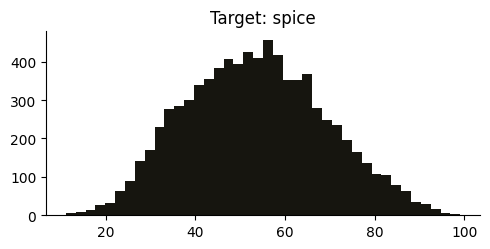

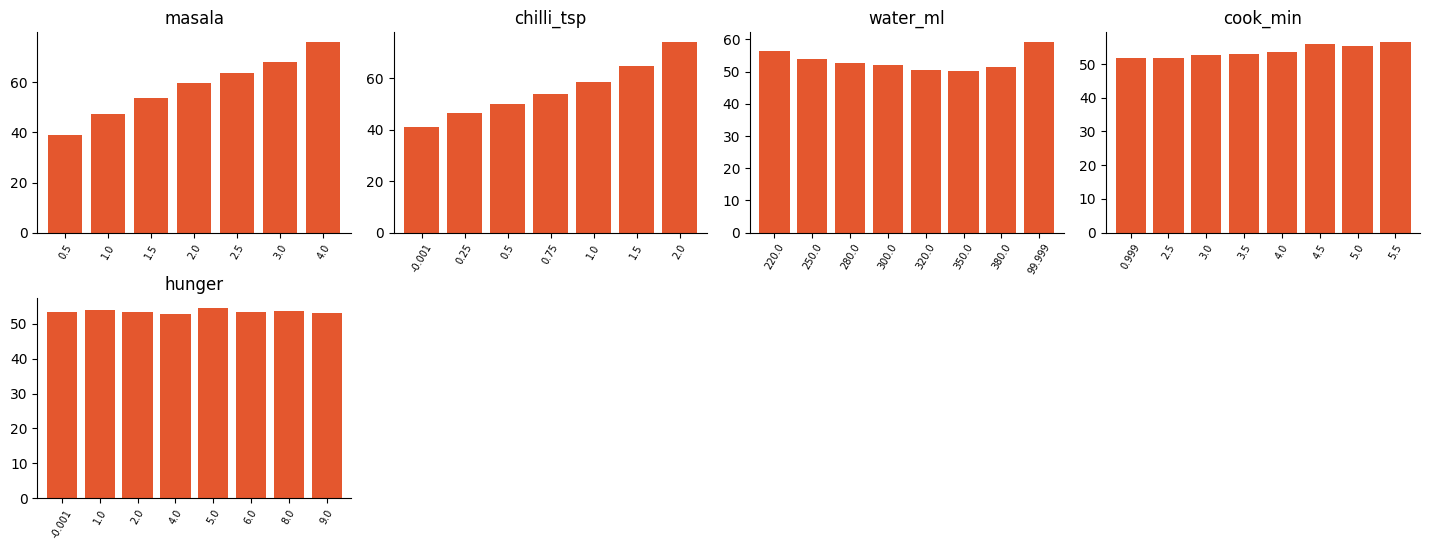

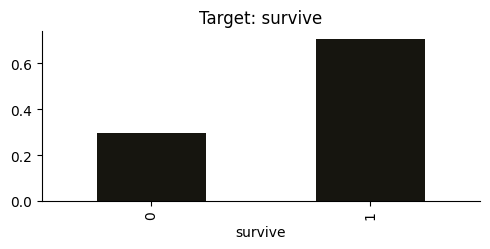

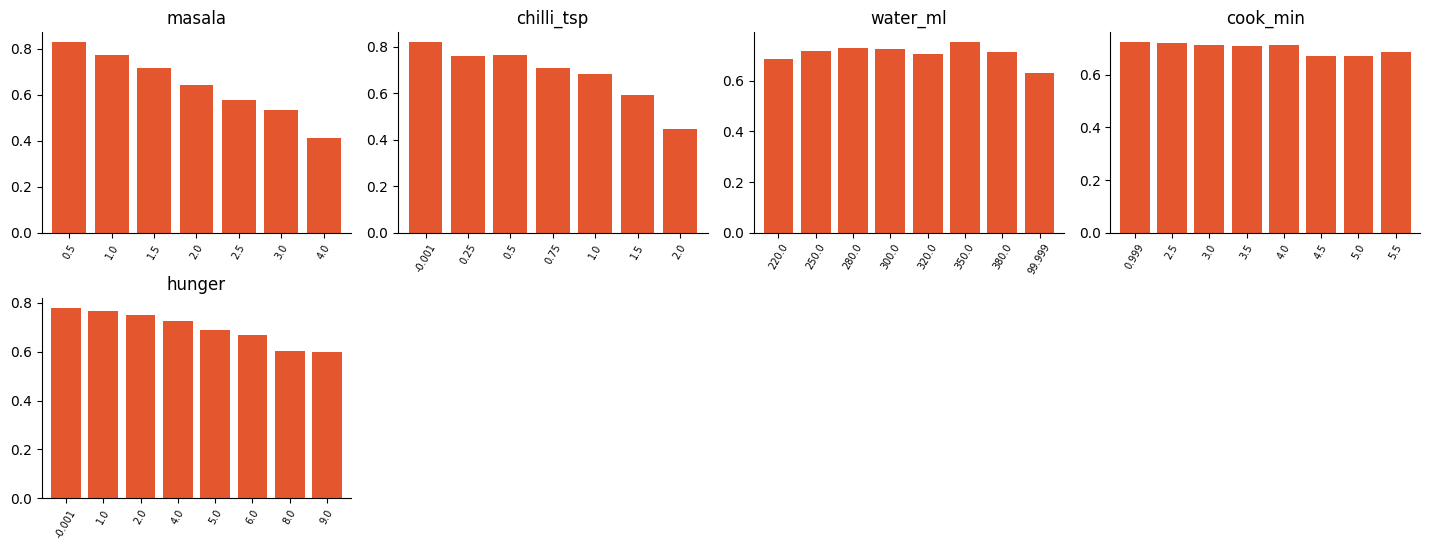

In [4]:
print("nulls:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
INPUTS = [Num("masala", 0, 4), Num("chilli_tsp", 0, 6), Num("water_ml", 100, 500), Num("cook_min", 1, 10), Num("hunger", 0, 10)]
RAW = [s["name"] for s in INPUTS]; eda(df, "spice", RAW, "regression"); eda(df, "survive", RAW)

## 3 · Features, split, train both heads

In [5]:
fz = Featurizer(INPUTS); tr, va, te = split3(df, "survive")
Xtr, Xva, Xte = fz.transform(tr), fz.transform(va), fz.transform(te)
spice, spice_val = train_regressor(Xtr, tr.spice.to_numpy(), Xva, va.spice.to_numpy(), depth=9, leaf=15)
surv, surv_name, table = train_classifier(Xtr, tr.survive, Xva, va.survive, depth=7, leaf=20)
print("spice head val:", {k: round(v, 3) for k, v in spice_val.items()}, "| survival head:", surv_name); table.round(4)

spice head val: {'val_mae': 5.676, 'ridge_baseline_val_mae': 6.1} | survival head: Logistic Regression


,model,val_log_loss,val_accuracy
0,Logistic Regression,0.5414,0.7358
1,Random Forest (isotonic-calibrated),0.5880,0.7258


## 4 · Test evaluation

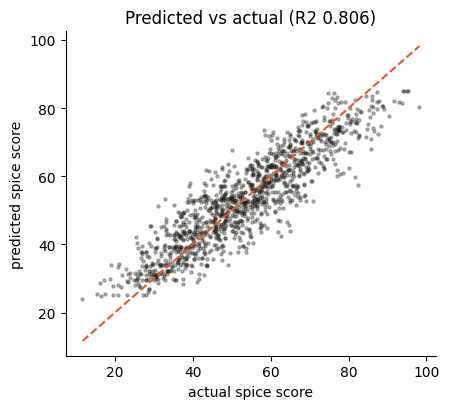

{'mae': 5.5205, 'r2': 0.8061}

In [6]:
m_spice = report_regression(spice, Xte, te.spice.to_numpy(), "spice score"); m_spice

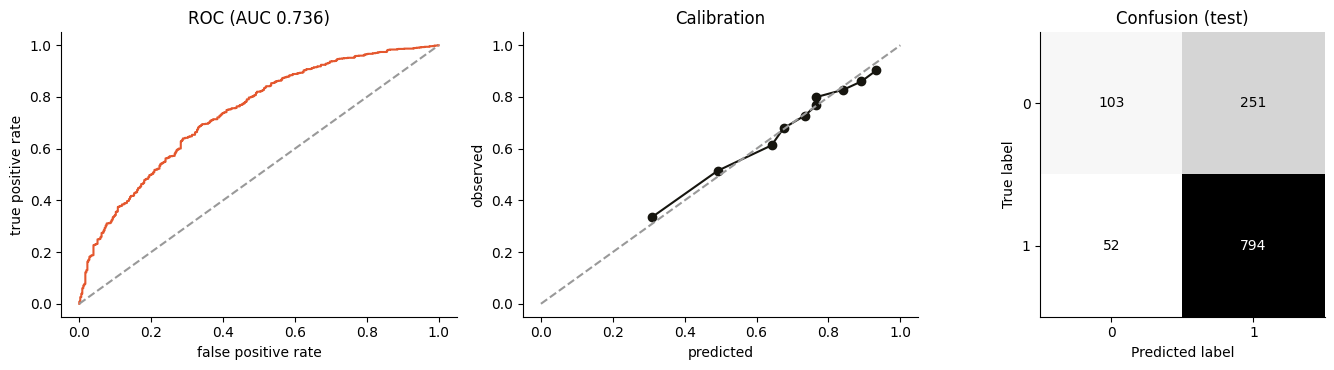

{'accuracy': 0.7475,
 'roc_auc': 0.7363,
 'log_loss': 0.5309,
 'brier': 0.1764,
 'oracle_auc': 0.7651}

In [7]:
m_surv = report_binary(surv, Xte, te.survive); m_surv["oracle_auc"] = round(float(roc_auc_score(te.survive, te.p_true)), 4); m_surv

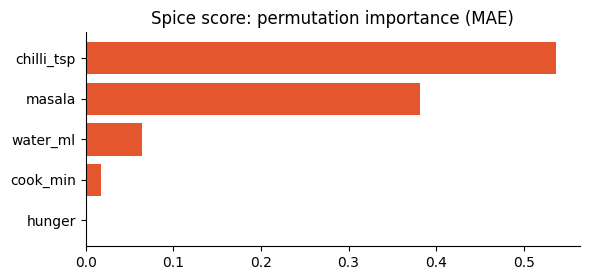

{'chilli_tsp': 0.5372,
 'masala': 0.3813,
 'water_ml': 0.064,
 'cook_min': 0.0175,
 'hunger': 0.0}

In [8]:
imp = group_importance(spice.predict, Xte, te.spice.to_numpy(), fz.groups, lambda y, p: np.mean(np.abs(y - p)))
plot_importance(imp, "Spice score: permutation importance (MAE)"); imp

In [9]:
ex = pd.DataFrame([dict(masala=2, chilli_tsp=3, water_ml=200, cook_min=5, hunger=8), dict(masala=1, chilli_tsp=0.5, water_ml=350, cook_min=3, hunger=4)])
X = fz.transform(ex); ex["spice"] = spice.predict(X).round(1); ex["P(survive)"] = surv.predict_proba(X)[:, 1].round(3); ex

,masala,chilli_tsp,water_ml,cook_min,hunger,spice,P(survive)
0,2,3.0,200,5,8,81.2,0.229
1,1,0.5,350,3,4,33.9,0.878


## 5 · Export + verify

In [10]:
heads = {"spice": export_head(spice, task="regression"), "survive": export_head(surv, labels=["no", "yes"])}
meta = make_metadata("v1.0", SEED, len(df), {"train": len(tr), "val": len(va), "test": len(te)},
    {"spice": {"algorithm": "Random Forest Regressor", "task": "regression", "metrics": m_spice, "val": {k: round(v, 3) for k, v in spice_val.items()}},
     "survive": {"algorithm": surv_name, "task": "binary", "metrics": m_surv, "candidates": table.round(4).to_dict("records")}},
    imp, ["Synthetic data: tolerance is hidden and simulated. Do not use this to decide anything about real food.", "Class bands (Safe / Suspicious / Dangerous / Call someone) are fixed thresholds on the spice score."], "generate() in train.ipynb")
write_artifacts("model", "maggi", "Will this Maggi become too spicy?", fz, tr, heads, {"spice": spice, "survive": surv}, meta, te[RAW])

wrote model (209 KB total) | export error vs sklearn: {'spice': 1.4713792831111963e-07, 'survive': 1.018021555942994e-09}


{'spice': 1.4713792831111963e-07, 'survive': 1.018021555942994e-09}